# Does a vision-language model read instructions and words like a reading-study participant?

| | |
| --- | --- |
| **Question** | Given instructions it must read from the screen, can a vision-language model monitor a rapid sequence of written words for a target category, and where in the model are the rule and the words represented? |
| **Subject** | Qwen2.5-VL-7B-Instruct (`qwen2.5-vl-7b-vwfa`: the registration plus a lesionable word-form region) |
| **Requires** | One GPU with 24 GB (run on an NVIDIA A10G), the model download (16.6 GB), about 45 minutes |
| **Lessons** | Experiments, sessions, behavior, perturbation, choosing units |

Every number below is computed in this notebook. Nothing is loaded from a previous run.

## Background

In a rapid serial visual presentation (RSVP) study, a participant first reads an instruction screen, then sees words one at a time, and answers once the sequence ends. Reading studies use it to separate *seeing* words from *deciding* about them, and lesion and imaging studies find a region of visual cortex (the visual word form area) whose damage impairs reading.

A vision-language model can take part in the same study: its vision tower encodes each screen, and its language decoder reads the encoded screens and answers. Two features of Qwen2.5-VL make the study informative:

- its vision tower encodes each image on its own and never sees the text the model is reading, so anything about the *rule* should appear in the language decoder, not in the vision tower;
- the instructions are an image, so the model must read the rule before it can follow it.

The stimuli are generated here: our own word lists rendered as images. No published benchmark is used.

## Hypotheses

Written before the run. Each one is tested against a null, and any of them can fail.

1. **The model follows instructions it reads.** Accuracy is above chance (50%) for both rules and both list lengths, and lower for six-word lists than for three-word lists.
2. **The rule lives in the language decoder, not the vision tower.** The vision tower's recording of each word is the same whichever rule was shown; the rule can be decoded from the language region above a shuffled-label null.
3. **The vision tower tells words from pseudowords.** Word and pseudoword images can be decoded apart from the vision tower's word-form layer above a shuffled-label null.
4. **Word-selective units matter more than any units.** Silencing the 128 most word-selective vision units lowers accuracy more than silencing 128 random units from the same layer.
5. **Confidence tracks correctness.** Reported confidence is higher on correct trials than on errors.

## Method

Each trial: an instruction screen (an image), then three or six word screens, then the response prompt. Two rules: *did any word name an animal?* and *did any word name a colour?* The **same word lists** are shown under both rules, so only the instruction differs. Each list contains an animal word or not, and a colour word or not, independently; the other words are ordinary nouns or pseudowords.

| Factor | Levels |
| --- | --- |
| Rule (instruction screen) | animal, colour |
| List length | 3, 6 words |
| Animal word in the list | yes, no |
| Colour word in the list | yes, no |
| Filler words | real nouns, pseudowords |

16 lists per length and filler cell gives 64 lists, 128 trials per condition.

## Setup

Imports, quiet output, and a temporary folder for the rendered screens and the experiment records.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

import random
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

WORK = Path(tempfile.mkdtemp())      # rendered screens and experiment records

## The subject

The registered Qwen2.5-VL-7B-Instruct with a `VWFA` region: the vision tower's word-form layer, which can be recorded and silenced. The `language_system` region is in the language decoder.

In [2]:
from brainscore import load_model

subject = load_model('qwen2.5-vl-7b-vwfa')
sorted(channel for channel in subject.out_channels if channel.startswith(('behavior', 'neural')))

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


['behavior',
 'behavior:choice',
 'behavior:confidence',
 'behavior:probabilities',
 'behavior:rating',
 'behavior:rt',
 'behavior:text',
 'neural:IT',
 'neural:V1',
 'neural:V2',
 'neural:V4',
 'neural:VWFA',
 'neural:language_system']

## The experiment

### Stimuli

The word lists. Fillers are ordinary nouns or pronounceable pseudowords; targets are animal and colour words.

In [3]:
ANIMALS = ['cat', 'dog', 'horse', 'lion', 'sheep', 'mouse', 'eagle', 'frog', 'tiger', 'whale']
COLOURS = ['red', 'blue', 'green', 'yellow', 'purple', 'orange', 'brown', 'pink', 'grey', 'violet']
NOUNS = ['table', 'chair', 'river', 'cloud', 'piano', 'ladder', 'window', 'candle', 'bottle', 'garden',
         'pencil', 'bridge', 'mirror', 'basket', 'hammer', 'pillow', 'castle', 'wallet', 'rocket', 'carpet']
PSEUDO = ['blick', 'florn', 'trave', 'gromp', 'snelt', 'pladge', 'vurk', 'mibble', 'strone', 'clanth',
          'drisp', 'wunter', 'pobe', 'frenk', 'sloat', 'grisk', 'thoven', 'brindle', 'quast', 'nallow']

Each word is drawn black on white, centred on a 448 x 160 image; instruction screens are 672 x 448 with one line of text per row.

In [4]:
FONT = ImageFont.load_default(size=64)

def render_word(word, path):
    """Draw one word, centred, on a white 448 x 160 image; return the file path."""
    image = Image.new('RGB', (448, 160), 'white')
    draw = ImageDraw.Draw(image)
    box = draw.textbbox((0, 0), word, font=FONT)
    draw.text(((448 - box[2]) / 2, (160 - box[3]) / 2), word, fill='black', font=FONT)
    image.save(path)
    return str(path)

def render_instruction(lines, path):
    """Draw the lines of an instruction screen on a white 672 x 448 image; return the file path."""
    image = Image.new('RGB', (672, 448), 'white')
    draw = ImageDraw.Draw(image)
    small = ImageFont.load_default(size=34)
    for i, line in enumerate(lines):
        draw.text((32, 40 + 52 * i), line, fill='black', font=small)
    image.save(path)
    return str(path)

The two instruction screens differ only in the last word of their last line.

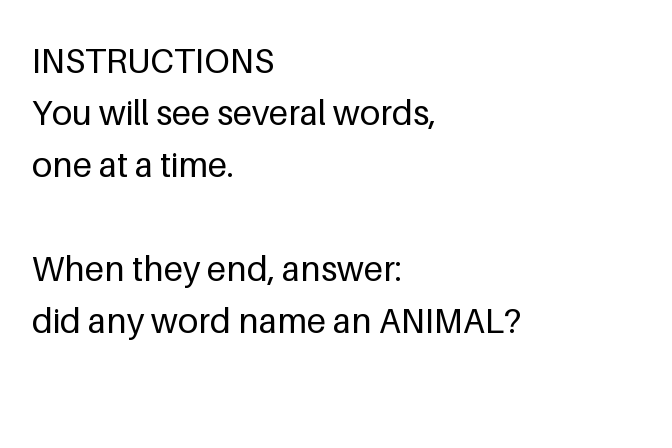

In [5]:
RULES = {
    'animal': ['INSTRUCTIONS', 'You will see several words,', 'one at a time.', '',
               'When they end, answer:', 'did any word name an ANIMAL?'],
    'colour': ['INSTRUCTIONS', 'You will see several words,', 'one at a time.', '',
               'When they end, answer:', 'did any word name a COLOUR?'],
}
instruction_images = {rule: render_instruction(lines, WORK / f'rule_{rule}.png') for rule, lines in RULES.items()}
Image.open(instruction_images['animal'])

The trials. `make_lists` balances the design: every combination of animal word present or absent, colour word present or absent, and filler type, with the targets inserted at random positions. `trial_table` shows each list under both rules and records the correct answer.

In [6]:
from brainscore_core.supported_data_standards.brainio.stimuli import StimulusSet

def make_lists(length, per_cell=4):
    lists = []
    for animal_in in (True, False):
        for colour_in in (True, False):
            for filler in ('noun', 'pseudo'):
                for rep in range(per_cell):
                    pool = NOUNS if filler == 'noun' else PSEUDO
                    words = random.sample(pool, length - animal_in - colour_in)   # fillers make up the rest
                    if animal_in:
                        words.insert(random.randrange(len(words) + 1), random.choice(ANIMALS))
                    if colour_in:
                        words.insert(random.randrange(len(words) + 1), random.choice(COLOURS))
                    lists.append(dict(words=words, animal_in=animal_in, colour_in=colour_in, filler=filler))
    return lists

def trial_table(length):
    rows = []
    for index, item in enumerate(make_lists(length)):
        for rule in RULES:                                   # the same list under both rules
            target_in = item['animal_in'] if rule == 'animal' else item['colour_in']
            row = dict(stimulus_id=f'L{length}-{index:02d}-{rule}', list_id=f'L{length}-{index:02d}',
                       rule=rule, length=length, filler=item['filler'],
                       animal_in=item['animal_in'], colour_in=item['colour_in'],
                       answer='yes' if target_in else 'no',
                       instruction=instruction_images[rule])
            for position, word in enumerate(item['words'], start=1):
                row[f'word_{position}'] = render_word(word, WORK / f'{row["list_id"]}_{position}.png')
                row[f'text_{position}'] = word
            rows.append(row)
    trials = StimulusSet(rows)
    trials.identifier = f'rsvp-reading-length{length}'
    return trials

random.seed(0)                       # fixes which words each list gets and where the targets go
np.random.seed(0)
trials = {length: trial_table(length) for length in (3, 6)}
trials[3][['stimulus_id', 'rule', 'text_1', 'text_2', 'text_3', 'answer']].head(6)

,stimulus_id,rule,text_1,text_2,text_3,answer
0,L3-00-animal,animal,mirror,grey,cat,yes
1,L3-00-colour,colour,mirror,grey,cat,yes
2,L3-01-animal,animal,pillow,orange,sheep,yes
3,L3-01-colour,colour,pillow,orange,sheep,yes
4,L3-02-animal,animal,purple,tiger,rocket,yes
5,L3-02-colour,colour,purple,tiger,rocket,yes


### Task

The task card says what the subject does and how it answers. There is no text instruction: the rule is on the first screen, and the model has to read it. The response is a choice with a reported confidence, and `present` gives the order of the screens. A second version asks for the model's implied probability of each answer, read from its likelihoods rather than its reply.

In [7]:
from brainscore_core import TaskContext
from brainscore_core.responses import Choice, Scale, trial_prompt

def task(length, probabilities=False):
    screens = ('image:instruction',) + tuple(f'image:word_{i}' for i in range(1, length + 1))
    if probabilities:
        return TaskContext(present=screens,
                           response=Choice(['yes', 'no'], probabilities=True))
    return TaskContext(present=screens,
                       response=Choice(['yes', 'no'], confidence=Scale(1, 5, 1)))

# What the subject receives on the first trial: the instruction image, then the word images.
[(kind, Path(value).name if kind == 'image' else value) for kind, value in trial_prompt(task(3), trials[3].iloc[0]).parts]

[('image', 'rule_animal.png'),
 ('image', 'L3-00_1.png'),
 ('image', 'L3-00_2.png'),
 ('image', 'L3-00_3.png'),
 ('text',
  'Answer with exactly one of: yes, no. Then, on a new line, rate your confidence from 1 to 5.')]

### Conditions

Three conditions: intact, word-selective units silenced, random units silenced.

The word-selective units come from a localizer, like an fMRI word-form localizer: separate words and pseudowords (not used in the task) shown passively, and the 128 units of the word-form layer that respond most to words over pseudowords. The matched control is 128 random units from the same layer.

In [8]:
localizer_words = ['apple', 'music', 'forest', 'letter', 'summer', 'doctor', 'kitchen', 'planet',
                   'button', 'island', 'market', 'silver', 'travel', 'winter', 'garage', 'jacket',
                   'number', 'office', 'pocket', 'record']
localizer_pseudo = ['plome', 'dranth', 'yuster', 'krell', 'spoft', 'vanosh', 'trolp', 'fendle',
                    'gaster', 'blorn', 'mirk', 'skell', 'pralt', 'thune', 'wiggen', 'cloft',
                    'drome', 'flisk', 'nerth', 'quoll']

localizer_rows = []
for kind, words in (('word', localizer_words), ('pseudo', localizer_pseudo)):
    for word in words:
        image = render_word(word, WORK / f'loc_{word}.png')
        localizer_rows.append(dict(stimulus_id=f'loc-{kind}-{word}', image_file_name=image, lexicality=kind))
localizer = StimulusSet(localizer_rows)
localizer.identifier = 'rsvp-localizer'
localizer.stimulus_paths = dict(zip(localizer['stimulus_id'], localizer['image_file_name']))

In [9]:
from brainscore.selection import FunctionalSelection, RandomSelection

K = 128
# Shows the localizer to the subject and keeps the K units with the largest word > pseudoword contrast.
word_units = FunctionalSelection('VWFA', localizer, contrast=(['word'], ['pseudo']),
                                 contrast_column='lexicality', n_units=K).resolve(subject)
population = word_units.metadata['unit_population']
random_units = RandomSelection(word_units.layer, n_units=K, n_total=len(population),
                               population=population, seed=0).resolve(subject)
subject.reset()
print(word_units.layer, len(word_units.indices), 'word-selective units;', len(random_units.indices), 'random units')

Activation cache bypassed: unsupported torch.dtype; define cache_config()


blocks.28 128 word-selective units; 128 random units


In [10]:
from brainscore_core import Perturbation, StateChange

def silence(selection):
    """A request to set the selected units to zero."""
    return StateChange(kind='ablation', target=selection, perturbation=Perturbation(kind='zero'))

CONDITIONS = ['intact', 'word_units', 'random_units']

## Run

One `Experiment` per list length, with the three conditions. The recorders ask for the answers and for two regions recorded during the same presentation: the vision tower's word-form layer (`VWFA`, one recording per screen) and the language region (one recording at the moment of answering).

A second, unrecorded run asks for the implied probabilities. Probabilities need extra forward passes, so they come from a separate presentation.

In [11]:
from brainscore.experiments import Experiment, Intervene, RecordBehavior, RecordNeural, TaskProtocol

results, implied = {}, {}
for length in (3, 6):
    results[length] = Experiment(
        subject=subject,
        protocol=TaskProtocol(trials[length], task(length), conditions=CONDITIONS),
        tools=[RecordNeural(['VWFA', 'language_system']), RecordBehavior(),
               Intervene(silence(word_units), conditions=['word_units'], name='silence_word_units'),
               Intervene(silence(random_units), conditions=['random_units'], name='silence_random_units')],
        output_dir=WORK / f'run_length{length}').run()
    implied[length] = Experiment(
        subject=subject, protocol=TaskProtocol(trials[length], task(length, probabilities=True)),
        tools=[RecordBehavior()], output_dir=WORK / f'implied_length{length}').run()
print('done')

done


## Read results back

### Answers

One row per trial and condition: whether the reply was a valid answer, whether it was correct, and the reported confidence. A trial whose reply could not be read as yes or no has no chosen answer and counts as incorrect.

In [12]:
def table(length, condition):
    choice = results[length].behavior(condition=condition)                  # (trials, yes/no)
    confidence = results[length].behavior(condition=condition, measure='confidence')
    frame = pd.DataFrame(trials[length])
    frame = frame[['stimulus_id', 'list_id', 'rule', 'length', 'filler', 'answer']].copy()
    frame['valid'] = choice['answer_valid'].values
    # The chosen answer is the column holding the largest value; unreadable replies are all NaN.
    chosen = np.where(np.isnan(choice.values).any(1), None, np.array(['yes', 'no'])[np.nan_to_num(choice.values).argmax(1)])
    frame['correct'] = [c == a for c, a in zip(chosen, frame['answer'])]
    frame['confidence'] = confidence.values
    frame['condition'] = condition
    return frame

behavior = pd.concat([table(length, condition) for length in (3, 6)
                      for condition in CONDITIONS], ignore_index=True)
behavior.groupby(['condition', 'length', 'rule'])['correct'].mean().unstack('rule').round(3)

rule                 animal  colour
condition    length                
intact       3        0.844   0.938
             6        0.781   0.781
random_units 3        0.906   0.938
             6        0.781   0.844
word_units   3        0.844   0.938
             6        0.812   0.906

The implied probability of the correct answer on each trial, from the second presentation.

In [13]:
p_correct = {}
for length in (3, 6):
    p = implied[length].behavior(measure='probabilities')                   # (trials, yes/no)
    answers = list(trials[length]['answer'])
    p_correct[length] = np.array([p.values[i, ['yes', 'no'].index(a)] for i, a in enumerate(answers)])
{length: values.shape for length, values in p_correct.items()}

{3: (64,), 6: (64,)}

### Recordings

`VWFA` holds one recording per screen (the instruction, then each word); `language_system` one recording per trial, at the moment of answering. Only the intact condition is used.

In [14]:
vwfa, language, rules, lists, words_only = {}, {}, {}, {}, {}
for length in (3, 6):
    vwfa[length] = results[length].neural('VWFA', condition='intact')
    language[length] = results[length].neural('language_system', condition='intact')
    rules[length] = np.array(list(vwfa[length]['rule'].values))
    lists[length] = np.array(list(vwfa[length]['list_id'].values))
    words_only[length] = np.asarray(vwfa[length].isel(part=slice(1, None)).values)   # drop the instruction screen
    print(length, 'VWFA', vwfa[length].shape, 'language', language[length].shape)

3 VWFA (64, 4, 1280) language (64, 3584)
6 VWFA (64, 7, 1280) language (64, 3584)


For hypothesis 3, every filler screen from the trials under the animal rule (so each list once), labelled word or pseudoword, grouped by list.

In [15]:
X, y, groups = [], [], []
for length in (3, 6):
    trial_rows = trials[length]
    keep = rules[length] == 'animal'                                    # each list once
    values = np.asarray(vwfa[length].values)[keep]
    rows = trial_rows[trial_rows['rule'] == 'animal'].reset_index(drop=True)
    for i, row in rows.iterrows():
        for position in range(1, length + 1):                           # screen 0 is the instruction
            word = row[f'text_{position}']
            if word in NOUNS or word in PSEUDO:
                X.append(values[i, position])
                y.append('word' if word in NOUNS else 'pseudo')
                groups.append(row['list_id'])
X, y, groups = np.array(X), np.array(y), np.array(groups)
X.shape

(224, 1280)

## Analysis

In [16]:
from scipy.stats import binomtest, fisher_exact, mannwhitneyu, wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def binomial_p(successes, n):
    """One-sided test that accuracy is above chance (50%)."""
    return binomtest(successes, n, 0.5, alternative='greater').pvalue

def decode(X, y, groups, shuffles=200, seed=0):
    """Cross-validated decoding accuracy (folds keep a list's trials together) and a shuffled-label null."""
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    cv = GroupKFold(n_splits=5)
    score = cross_val_score(model, X, y, groups=groups, cv=cv).mean()
    rng = np.random.default_rng(seed)
    null = [cross_val_score(model, X, rng.permutation(y), groups=groups, cv=cv).mean() for _ in range(shuffles)]
    return score, float(np.mean(np.array(null) >= score))

def max_rule_difference(words_only, lists):
    """Largest difference between the two rules' recordings of the same list's word screens."""
    by_list = {}
    for i, list_id in enumerate(lists):
        by_list.setdefault(list_id, []).append(words_only[i])
    return float(max(np.abs(a - b).max() for a, b in by_list.values()))

def bootstrap_drop(behavior, condition, n=2000, seed=0):
    """Accuracy drop from intact, with a 95% interval resampling lists."""
    rng = np.random.default_rng(seed)
    merged = behavior[behavior.condition == 'intact'].set_index('stimulus_id')[['list_id', 'correct']].join(
        behavior[behavior.condition == condition].set_index('stimulus_id')['correct'].rename('changed'))
    lists = merged['list_id'].unique()
    drops = []
    for _ in range(n):
        sample = merged[merged['list_id'].isin(rng.choice(lists, len(lists)))]
        drops.append(sample['correct'].mean() - sample['changed'].mean())
    observed = merged['correct'].mean() - merged['changed'].mean()
    return observed, np.percentile(drops, [2.5, 97.5])

## Results

### 1. Does the model follow instructions it reads?

In [17]:
intact = behavior[behavior.condition == 'intact']
by_cell = intact.groupby(['length', 'rule'])['correct'].agg(['mean', 'count'])
print(by_cell.round(3))
print('invalid replies:', int((~intact.valid).sum()), 'of', len(intact))
for length in (3, 6):
    print(f'length {length}: mean implied p(correct) = {np.mean(p_correct[length]):.3f}')

for (length, rule), row in by_cell.iterrows():
    print(f'length {length}, {rule}: p (above chance) = {binomial_p(int(row["mean"] * row["count"]), int(row["count"])):.2g}')
three, six = intact[intact.length == 3].correct, intact[intact.length == 6].correct
print('six-word lists worse than three-word lists: p =',
      round(fisher_exact([[three.sum(), (~three).sum()], [six.sum(), (~six).sum()]], alternative='greater')[1], 4))

                mean  count
length rule                
3      animal  0.844     32
       colour  0.938     32
6      animal  0.781     32
       colour  0.781     32
invalid replies: 0 of 128
length 3: mean implied p(correct) = 0.969
length 6: mean implied p(correct) = 0.938
length 3, animal: p (above chance) = 5.7e-05
length 3, colour: p (above chance) = 1.2e-07
length 6, animal: p (above chance) = 0.0011
length 6, colour: p (above chance) = 0.0011
six-word lists worse than three-word lists: p = 0.0755


### 2. Where is the rule?

The same list is shown under both rules. If the vision tower never sees the rule, its recording of each word must be identical across rules; the language region, read at the moment of answering, should carry the rule.

In [18]:
for length in (3, 6):
    print(f'length {length}: vision tower, word screens, max difference between rules =',
          max_rule_difference(words_only[length], lists[length]))
    score, p = decode(np.asarray(language[length].values), rules[length], lists[length], shuffles=100)
    print(f'length {length}: rule decoded from the language region: {score:.3f} (shuffled-label null p = {p:.3f})')
    flat = words_only[length].reshape(len(words_only[length]), -1)     # one row per trial: all word screens
    score, p = decode(flat, rules[length], lists[length], shuffles=100)
    print(f'length {length}: rule decoded from the vision tower word screens: {score:.3f} (p = {p:.3f})')

length 3: vision tower, word screens, max difference between rules = 0.0


length 3: rule decoded from the language region: 1.000 (shuffled-label null p = 0.000)


length 3: rule decoded from the vision tower word screens: 0.500 (p = 0.370)
length 6: vision tower, word screens, max difference between rules = 0.0


length 6: rule decoded from the language region: 1.000 (shuffled-label null p = 0.000)


length 6: rule decoded from the vision tower word screens: 0.500 (p = 0.440)


### 3. Does the vision tower tell words from pseudowords?

Each filler screen is one recording; folds keep each list's screens together.

In [19]:
score, p = decode(X, y, groups, shuffles=100)
print(f'words vs pseudowords from the word-form layer: {score:.3f} (shuffled-label null p = {p:.3f}, n = {len(y)} screens)')

words vs pseudowords from the word-form layer: 1.000 (shuffled-label null p = 0.000, n = 224 screens)


### 4. Do word-selective units matter more than any units?

In [20]:
for condition in ('word_units', 'random_units'):
    observed, interval = bootstrap_drop(behavior, condition)
    print(f'{condition}: accuracy drop {observed:+.3f}, 95% CI [{interval[0]:+.3f}, {interval[1]:+.3f}]')

# Per trial: 1 where only the word-selective lesion made the trial wrong, -1 where only the random one did.
paired = behavior[behavior.condition != 'intact'].pivot_table(index='stimulus_id', columns='condition', values='correct')
difference = paired['random_units'].astype(float) - paired['word_units'].astype(float)
print('word-selective lesion worse than random (per trial): mean difference',
      round(difference.mean(), 3), ', p =', round(wilcoxon(difference[difference != 0], alternative='greater').pvalue, 4)
      if (difference != 0).any() else 'no differing trials')

word_units: accuracy drop -0.039, 95% CI [-0.069, -0.011]


random_units: accuracy drop -0.031, 95% CI [-0.066, +0.000]
word-selective lesion worse than random (per trial): mean difference -0.008 , p = 0.7734


### 5. Does confidence track correctness?

In [21]:
valid = intact[intact.valid & intact.confidence.notna()]
print(valid.groupby('correct')['confidence'].describe()[['count', 'mean']].round(2))
if valid.correct.nunique() == 2:
    print('confidence higher when correct: p =',
          round(mannwhitneyu(valid[valid.correct].confidence, valid[~valid.correct].confidence,
                             alternative='greater').pvalue, 4))
else:
    print('every trial was', 'correct' if valid.correct.all() else 'wrong', '- the comparison cannot be made')

         count  mean
correct             
False     21.0   2.0
True     107.0   2.8
confidence higher when correct: p = 0.0002


## Conclusion and limits

| Hypothesis | This run | Verdict |
| --- | --- | --- |
| 1. Follows instructions it reads | Intact accuracy 0.84 (animal) and 0.94 (colour) for three words, 0.78 and 0.78 for six; every cell above chance (p ≤ 0.002). Six-word lists were not reliably harder than three-word lists (p = 0.08). Mean implied p(correct) 0.97 and 0.94. | **Supported**; no reliable effect of list length. |
| 2. The rule is in the language decoder, not the vision tower | Vision tower recordings of the same words are identical across rules (largest difference 0.0); the rule is decoded from them at chance (0.50). The language region decodes the rule perfectly (1.00; shuffled-label null p < 0.01). | **Supported**, with the caveat below. |
| 3. The vision tower tells words from pseudowords | Decoded perfectly from the word-form layer (1.00 over 224 screens; null p < 0.01). | **Supported**. |
| 4. Word-selective units matter more than any units | Silencing the 128 word-selective units changed accuracy by +0.04 (95% CI +0.01 to +0.07); 128 random units by +0.03 (0.00 to +0.07). No difference between them (p = 0.8). | **Not supported**: neither lesion hurt; both slightly helped. |
| 5. Confidence tracks correctness | Mean confidence 2.8 when correct, 2.0 on errors (p < 0.001). | **Supported**, though confidence stays in the lower half of the 1-5 scale. |

The model reads the rule from the screen, follows it on most trials, and is less sure when it is wrong. The vision tower separates words from pseudowords but carries nothing about the rule; the rule appears only in the language decoder. Silencing 10% of one vision layer's units, chosen as word-selective or at random, did not impair reading: at this size and lesion, the 7B's reading is robust. A larger lesion, another layer, or the language decoder may differ.

Limits:

- **Why the 7B.** In a pilot of 16 balanced trials, Qwen2.5-VL-3B answered "no" to nearly every list shown as separate word screens (13% of targets found), although it solved the same lists as text (88%). It could not combine words across separate images. The 7B solved all 16, so it is the subject here.
- **One model, one seed, synthetic stimuli.** The word lists are short and the screens are clean renders; the result says what this model does on these screens, not how it reads in general.
- **The vision tower cannot see the rule by construction**, so hypothesis 2's vision half is a check of the pipeline as much as a finding. The two instruction screens also differ as images, so decoding the rule from the language region shows the rule is present there, not how the model uses it.
- **The lesion is in the vision tower only**, at one layer, and the localizer used 20 words and 20 pseudowords. A different layer or localizer may select different units.
- **Probabilities come from a second presentation.** The answers and recordings come from one presentation; the implied probabilities from another, unrecorded one.
- **The decoders are linear and regularized**; a null based on shuffled labels with list-grouped folds is the comparison, not chance.
- **Answers near a tie depend on the hardware.** The model generates in bfloat16, so a few six-word trials are answered differently on different GPUs. The numbers here come from an NVIDIA L4; on an A10G, six-word colour accuracy was 0.75 and the length effect p = 0.05. Every other verdict is the same on both.